# **Mobile Price Prediction Model**
----------------------------------

#### 1.	Download the dataset from above link and load it into your Python environment.

In [155]:
import pandas as pd
import numpy as np
import seaborn as sns
import statistics as stat
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, r2_score
sheet_id = "1vKfnJEhdWQEZyHKvCQCC7ko1qJzadIYa5KNPXh934B0"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv"

cellphone_df = pd.read_csv(url)
cellphone_df.head(10)

,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,203,2357,10,135.0,5.2,424,8,1.35,16.0,3.000,13.00,8.0,2610,7.4
1,880,1749,10,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
2,40,1916,10,110.0,4.7,312,4,1.20,8.0,1.500,13.00,5.0,2000,7.6
3,99,1315,11,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
4,880,1749,11,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
5,947,2137,12,150.0,5.5,401,4,2.30,16.0,2.000,16.00,8.0,2500,9.5
6,774,1238,13,134.1,4.0,233,2,1.20,8.0,1.000,2.00,0.0,1560,11.7
7,947,2137,13,150.0,5.5,401,4,2.30,16.0,2.000,16.00,8.0,2500,9.5
8,99,1315,14,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
9,1103,2580,15,145.0,5.1,432,4,2.50,16.0,2.000,16.00,2.0,2800,8.1


#### 2.	Perform the EDA and do the visualizations.

In [156]:
cellphone_df.nunique()

Product_id       83
Price            81
Sale            125
weight           62
resoloution      24
ppi              45
cpu core          6
cpu freq         28
internal mem     10
ram              12
RearCam          18
Front_Cam        15
battery          55
thickness        49
dtype: int64

In [157]:
cellphone_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_id    161 non-null    int64  
 1   Price         161 non-null    int64  
 2   Sale          161 non-null    int64  
 3   weight        161 non-null    float64
 4   resoloution   161 non-null    float64
 5   ppi           161 non-null    int64  
 6   cpu core      161 non-null    int64  
 7   cpu freq      161 non-null    float64
 8   internal mem  161 non-null    float64
 9   ram           161 non-null    float64
 10  RearCam       161 non-null    float64
 11  Front_Cam     161 non-null    float64
 12  battery       161 non-null    int64  
 13  thickness     161 non-null    float64
dtypes: float64(8), int64(6)
memory usage: 17.7 KB


In [158]:
cellphone_df.shape

(161, 14)

In [159]:
cellphone_df.describe()

,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,675.559006,2215.596273,621.465839,170.426087,5.209938,335.055901,4.857143,1.502832,24.501714,2.204994,10.378261,4.503106,2842.111801,8.921739
std,410.851583,768.187171,1546.618517,92.888612,1.509953,134.826659,2.444016,0.599783,28.804773,1.609831,6.181585,4.342053,1366.990838,2.192564
min,10.000000,614.000000,10.000000,66.000000,1.400000,121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,800.000000,5.100000
25%,237.000000,1734.000000,37.000000,134.100000,4.800000,233.000000,4.000000,1.200000,8.000000,1.000000,5.000000,0.000000,2040.000000,7.600000
50%,774.000000,2258.000000,106.000000,153.000000,5.150000,294.000000,4.000000,1.400000,16.000000,2.000000,12.000000,5.000000,2800.000000,8.400000
75%,1026.000000,2744.000000,382.000000,170.000000,5.500000,428.000000,8.000000,1.875000,32.000000,3.000000,16.000000,8.000000,3240.000000,9.800000
max,1339.000000,4361.000000,9807.000000,753.000000,12.200000,806.000000,8.000000,2.700000,128.000000,6.000000,23.000000,20.000000,9500.000000,18.500000


In [160]:
cellphone_df.drop(columns=["Product_id"], inplace=True)

In [161]:
cellphone_df.isnull().sum().sort_values(ascending=False)

Price           0
Sale            0
weight          0
resoloution     0
ppi             0
cpu core        0
cpu freq        0
internal mem    0
ram             0
RearCam         0
Front_Cam       0
battery         0
thickness       0
dtype: int64

In [162]:
cellphone_df.duplicated().sum()

np.int64(0)

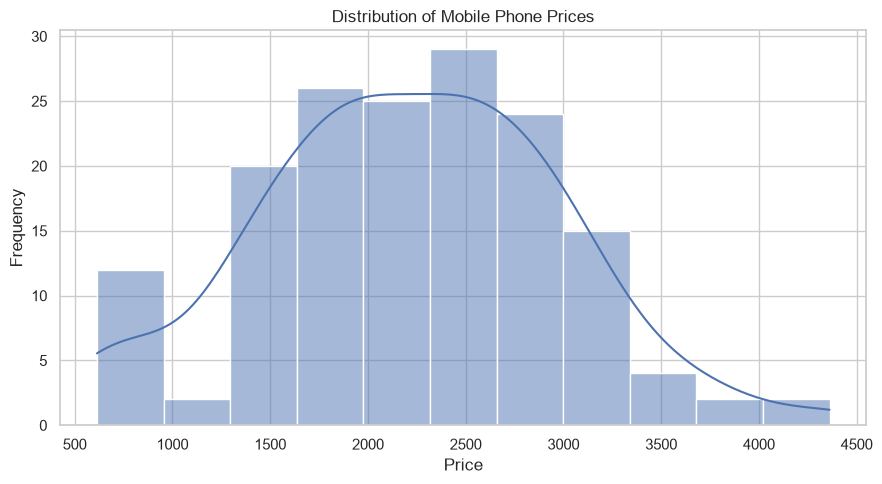

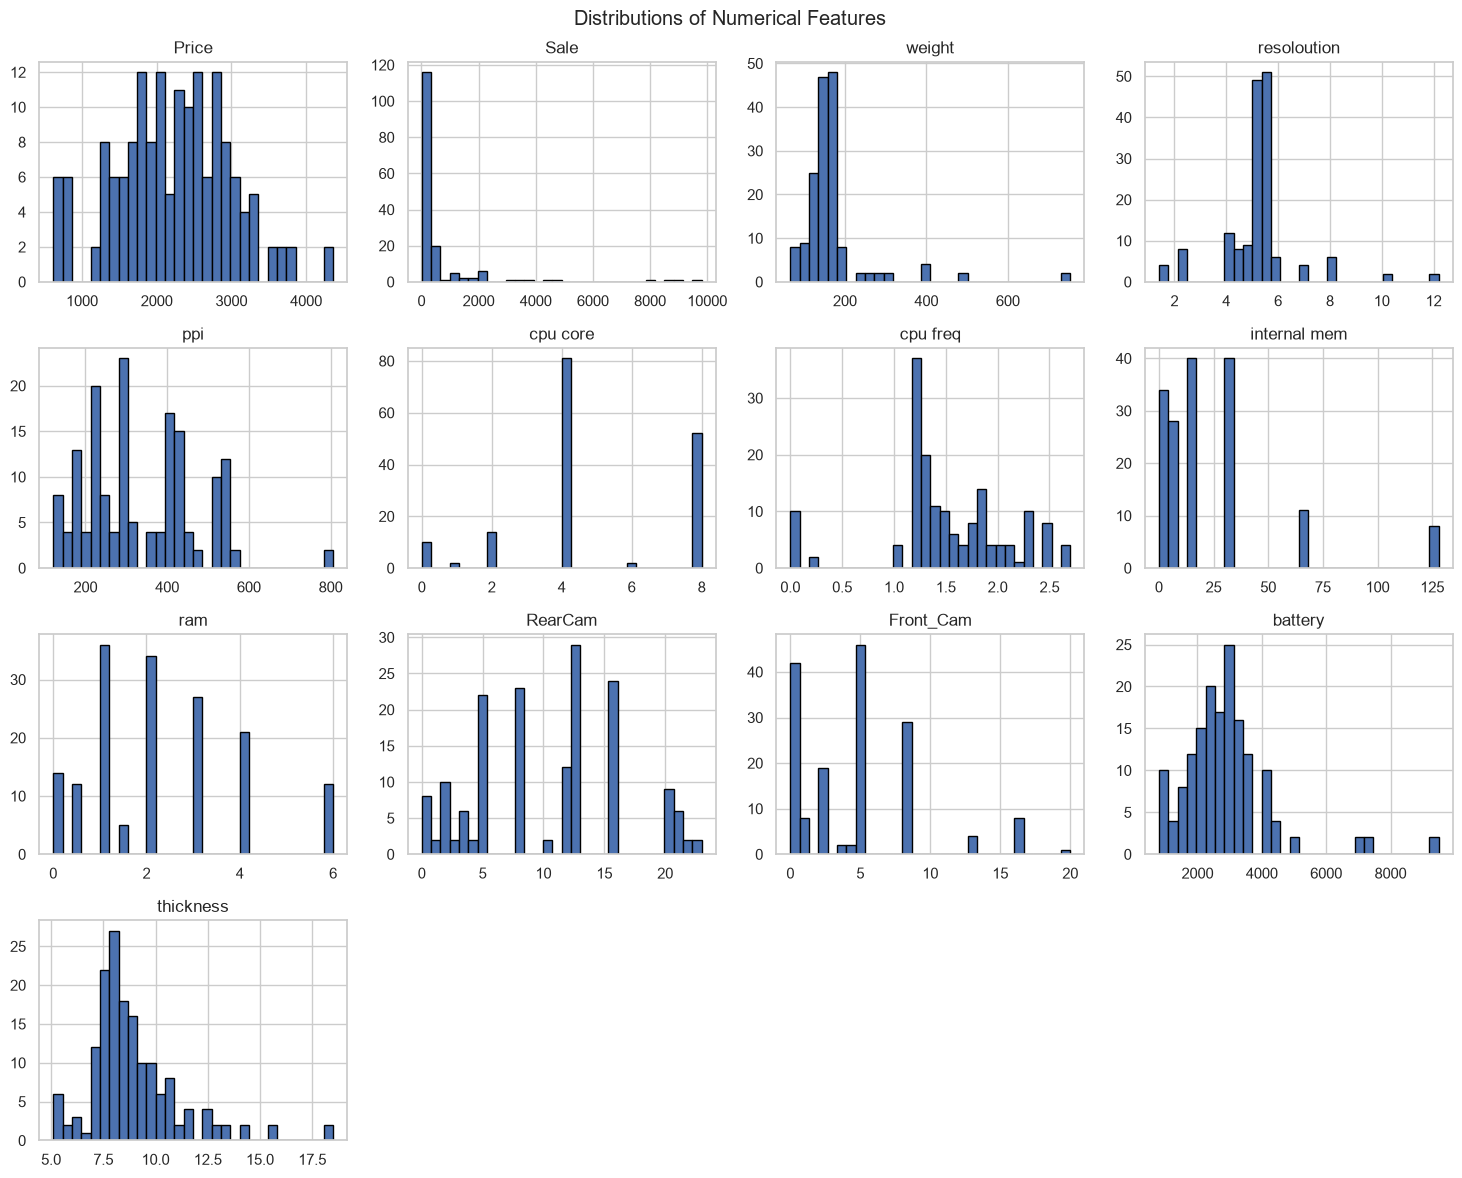

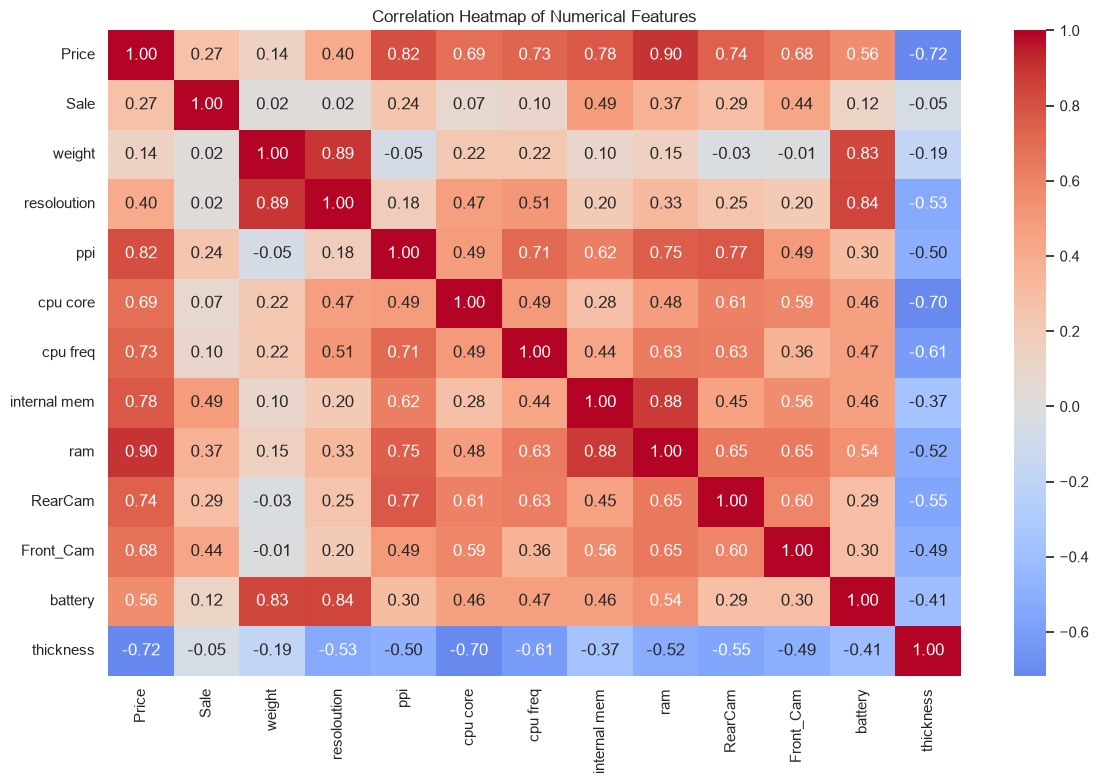

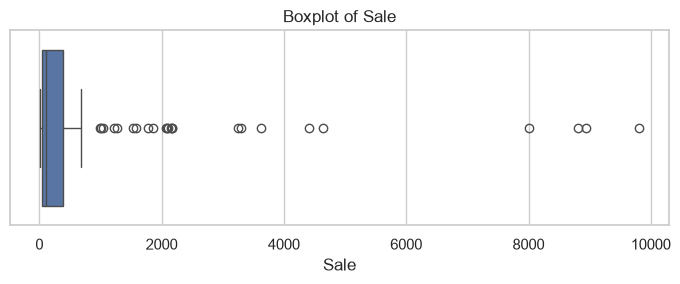

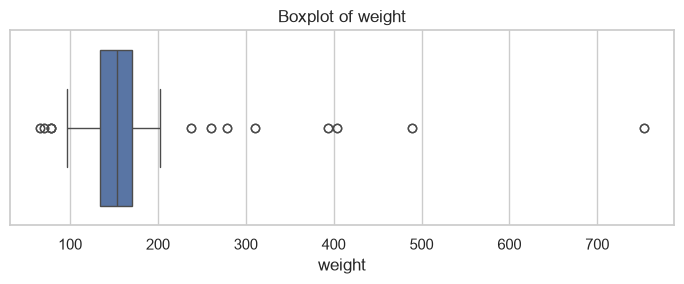

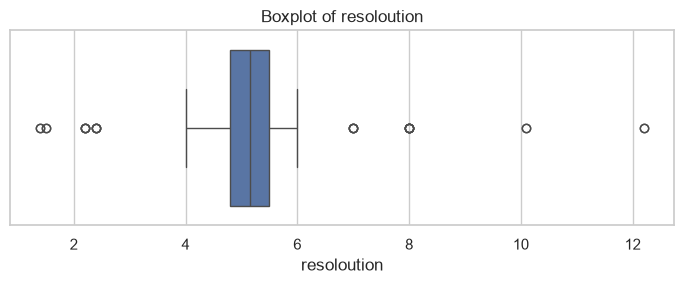

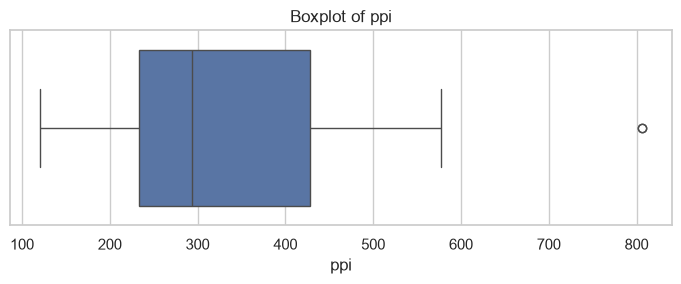

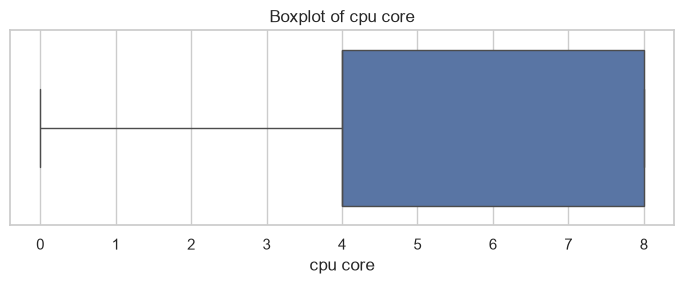

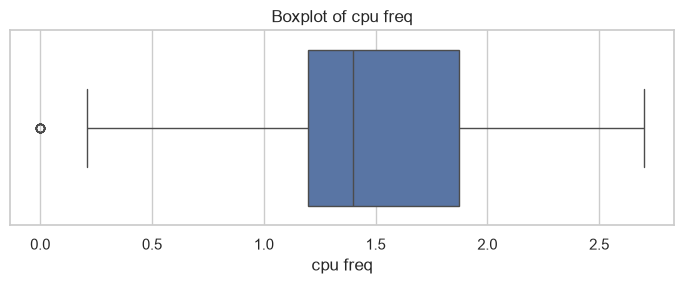

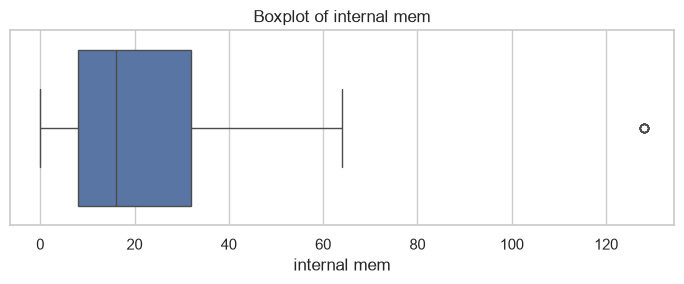

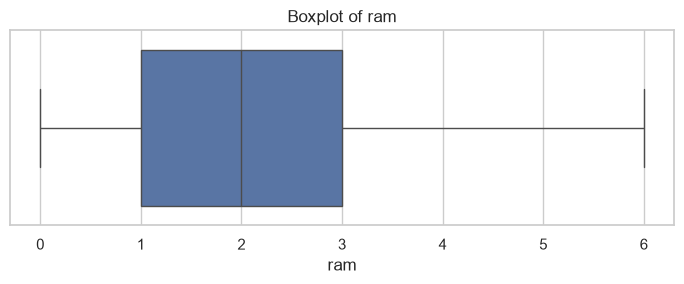

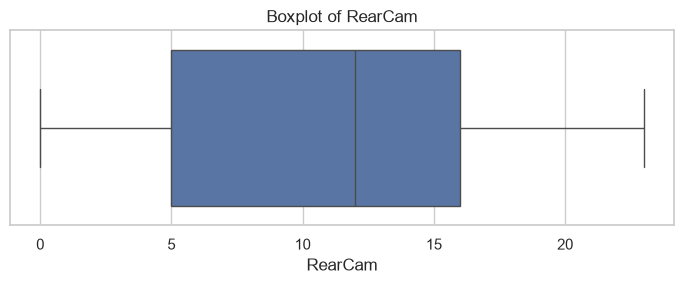

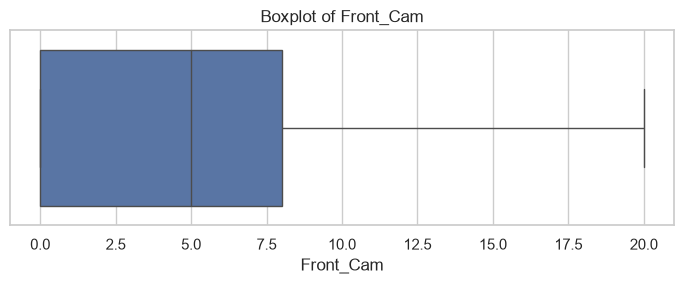

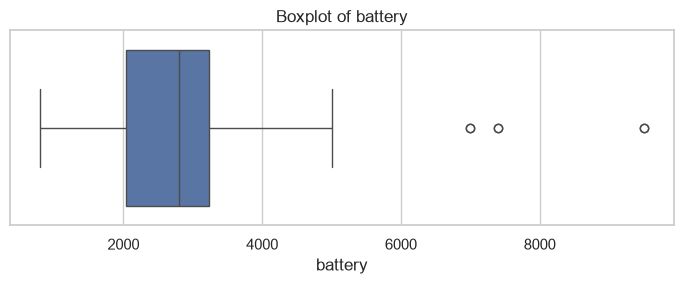

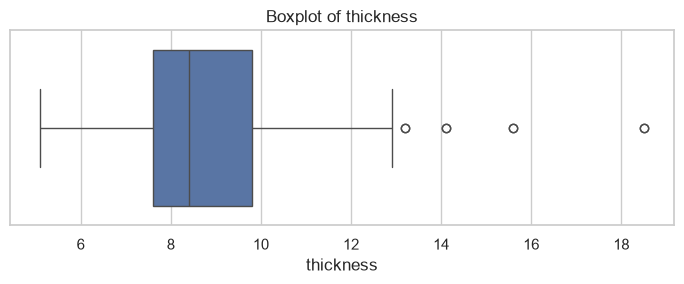

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")

# Identify numerical columns, excluding the identifier
numeric_cols = cellphone_df.select_dtypes(
    include=np.number
).columns.drop("Product_id", errors="ignore")

# 1. Distribution of phone prices
plt.figure(figsize=(9, 5))
sns.histplot(cellphone_df["Price"], kde=True)
plt.title("Distribution of Mobile Phone Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 2. Distributions of numerical features
cellphone_df[numeric_cols].hist(
    figsize=(15, 12), bins=30, edgecolor="black"
)
plt.suptitle("Distributions of Numerical Features")
plt.tight_layout()
plt.show()

# 3. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    cellphone_df[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# 4. Relationships between selected features and price
candidate_features = [
    col for col in ["RAM", "ROM", "Battery",
                    "Mobile_Size", "Primary_Cam", "Selfi_Cam"]
    if col in cellphone_df.columns
]

for col in candidate_features:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=cellphone_df, x=col, y="Price")
    plt.title(f"{col} vs Mobile Phone Price")
    plt.tight_layout()
    plt.show()

# 5. Boxplots for identifying potential outliers
for col in numeric_cols:
    if col != "Price":
        plt.figure(figsize=(7, 3))
        sns.boxplot(x=cellphone_df[col])
        plt.title(f"Boxplot of {col}")
        plt.tight_layout()
        plt.show()

#### 3.	Check the distributions/skewness in the variables and do the transformations if required.

In [164]:
# Calculate skewness for numeric features; product IDs are not measurements.
numeric_cols = cellphone_df.select_dtypes(include=[np.number]).columns.drop(
    "Product_id", errors="ignore"
)
skewness_dict = cellphone_df[numeric_cols].skew().to_dict()

print(f"{'Variable':<15} | {'Skewness Value':<15} | {'Skewness Category'}")
print("-" * 55)

for col, val in skewness_dict.items():
    abs_val = abs(val)
    if abs_val < 0.5:
        category = "Low"
    elif abs_val < 1.0:
        category = "Moderate"
    else:
        category = "High"
    
    print(f"{col:<15} | {val:<15.4f} | {category}")

Variable        | Skewness Value  | Skewness Category
-------------------------------------------------------
Price           | 0.0523          | Low
Sale            | 4.2694          | High
weight          | 3.9818          | High
resoloution     | 1.1761          | High
ppi             | 0.6025          | Moderate
cpu core        | -0.0091         | Low
cpu freq        | -0.5127         | Moderate
internal mem    | 2.3897          | High
ram             | 0.7927          | Moderate
RearCam         | 0.1069          | Low
Front_Cam       | 1.1697          | High
battery         | 2.0927          | High
thickness       | 1.5877          | High


In [165]:
from scipy.stats import boxcox

# Identify highly skewed columns based on the threshold (absolute skewness >= 1.0)
highly_skewed_cols = [col for col, val in skewness_dict.items() if abs(val) >= 1.0]
print("Highly skewed columns identified:", highly_skewed_cols)

# Create a copy of the dataframe to store transformed features
cellphone_transformed = cellphone_df.copy()

print("\nApplying Box-Cox transformation:")
for col in highly_skewed_cols:
    # Box-Cox requires strictly positive values (x > 0)
    if (cellphone_transformed[col] <= 0).any():
        # Add a constant shift of 1 to make all values positive
        shifted_data = cellphone_transformed[col] + 1
        transformed_data, fitted_lambda = boxcox(shifted_data)
        cellphone_transformed[col] = transformed_data
        print(f"{col:<15} | Shifted by +1 | Lambda: {fitted_lambda:.4f} | New Skew: {cellphone_transformed[col].skew():.4f}")
    else:
        transformed_data, fitted_lambda = boxcox(cellphone_transformed[col])
        cellphone_transformed[col] = transformed_data
        print(f"{col:<15} | No shift      | Lambda: {fitted_lambda:.4f} | New Skew: {cellphone_transformed[col].skew():.4f}")

Highly skewed columns identified: ['Sale', 'weight', 'resoloution', 'internal mem', 'Front_Cam', 'battery', 'thickness']

Applying Box-Cox transformation:
Sale            | No shift      | Lambda: -0.1648 | New Skew: 0.0801
weight          | No shift      | Lambda: -0.5749 | New Skew: -0.1640
resoloution     | No shift      | Lambda: 0.6848 | New Skew: 0.2772
internal mem    | Shifted by +1 | Lambda: 0.1805 | New Skew: -0.0080
Front_Cam       | Shifted by +1 | Lambda: 0.2154 | New Skew: -0.0768
battery         | No shift      | Lambda: 0.1840 | New Skew: 0.0341
thickness       | No shift      | Lambda: -0.4906 | New Skew: -0.0422


#### 5.	Create a ML model to predict the price of the phone based on the specifications given

In [166]:
x = cellphone_df.drop(columns=["Price"])
y = cellphone_df["Price"]

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [167]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

xtrain = pd.DataFrame(
    scaler.fit_transform(xtrain),
    columns=xtrain.columns,
    index=xtrain.index
)

xtest = pd.DataFrame(
    scaler.transform(xtest),
    columns=xtest.columns,
    index=xtest.index
)

display(xtrain.head())

,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
115,-0.220615,0.064071,0.351148,1.303784,-0.36068,0.700967,0.246710,1.121291,0.919051,0.070159,0.289210,-0.585008
2,-0.397968,-0.683076,-0.319202,-0.150404,-0.36068,-0.465309,-0.570668,-0.435058,0.443103,0.070159,-0.629752,-0.585008
123,-0.167232,0.306894,0.351148,-0.541081,-0.36068,-0.465309,-0.298209,-0.123788,-0.350144,-0.832388,0.442370,0.544944
45,-0.380173,-0.437918,-0.118097,-0.280630,-0.36068,-0.292527,-0.298209,-0.123788,0.443103,0.070159,-0.246851,-0.106952
42,-0.381360,-0.408733,-0.453272,-0.830472,-0.36068,-0.292527,-0.570668,-0.746328,-0.826093,-1.058025,-0.936072,0.501484


In [168]:
model = LinearRegression()
model.fit(xtrain, ytrain)

y_pred = model.predict(xtest)


In [169]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
y_train_pred = model.predict(xtrain)
y_test_pred = model.predict(xtest)

print(f"Training R²: {model.score(xtrain, ytrain):.4f}")
print(f"Testing R²:  {model.score(xtest, ytest):.4f}")  
print(f"Test MAE:    {mean_absolute_error(ytest, y_test_pred):.2f}")
print(f"Test RMSE:   {np.sqrt(mean_squared_error(ytest, y_test_pred)):.2f}")

prediction_results = pd.DataFrame({
    "Actual Price": ytest,
    "Predicted Price": y_test_pred
})
display(prediction_results)

Training R²: 0.9516
Testing R²:  0.9614
Test MAE:    123.46
Test RMSE:   147.92


,Actual Price,Predicted Price
105,833,893.759073
108,1676,1868.526144
142,2508,2595.273983
55,1777,1527.976280
94,1511,1615.642552
29,1950,1862.751652
101,833,893.980282
51,1347,1342.963884
100,2343,2362.560732
143,2508,2594.278542


In [172]:
import joblib
joblib.dump(model, "mobile_price_prediction_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [171]:
# Example values for a sample mobile phone; edit these or enter values when prompted.
sample_values = {
    "Sale": 100,
    "weight": 150,
    "resoloution": 5.5,
    "ppi": 400,
    "cpu core": 8,
    "cpu freq": 2.0,
    "internal mem": 64,
    "ram": 4,
    "RearCam": 16,
    "Front_Cam": 8,
    "battery": 4000,
    "thickness": 8.0
}

feature_names = list(xtrain.columns)
mobile_input = {}

for feature in feature_names:
    default = sample_values[feature]
    raw_value = input(f"{feature} (sample {default}): ").strip()
    mobile_input[feature] = float(raw_value) if raw_value else default

input_df = pd.DataFrame([mobile_input], columns=feature_names)
input_scaled = pd.DataFrame(
    scaler.transform(input_df),
    columns=feature_names
)

predicted_price = model.predict(input_scaled)[0]

display(input_df)
print(f"Predicted mobile price: {predicted_price:.2f}")

,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,100,150,5.5,400,8,2.0,64,4,16,8,4000,8.0


Predicted mobile price: 3169.93
